# Knockouts, the cell cycle and heterogeneity

The project goal has two halves: read out cell-cycle state from morphology, then **normalise or regress the cell cycle out of
perturbation profiles and test whether that reduces the apparent heterogeneity of perturbed populations**. Notebooks 16 and 17
built and aligned the cell-cycle readout. This notebook uses it on the knockouts:

1. **Cells of perturbations likely to affect the cycle** (building on Brian's CDK7 / CCNB1 figures): which knockouts shift the
   cell-cycle distribution, compared fairly against non-targeting controls, and checked against measured 4i markers.
2. **The whole library** (1,000 OPS0077 knockouts, 591,136 cells): cycle shifts, and heterogeneity before and after regressing the cycle out.
3. **Three questions about cycle normalisation.** Does it (1) reduce field and well heterogeneity, (2) find perturbations that
   change the cell-cycle distribution, and (3) separate those from perturbations that change the cells themselves?
4. **A cell-cycle representation of the CROP-seq knockouts**, and how it maps to phase-contrast morphology.

> **"phase" is used for two things.** *Cell-cycle phase* (G1/S/G2/M, or the angle `cc_phase`) is what we read out.
> *Phase contrast* (label-free) is the imaging modality. Phase-contrast **morphology** is always the predictor here.

**Model.** Phase-contrast OrganelleProfiler features -> PCA-100 -> ridge to the sine and cosine of the 4i `cc_phase` (circular
regression), and logistic regression to the DNA-content class (4N vs 2N, measured DAPI). Both are trained on NTC cells only, with folds
grouped by imaging tile. Out of fold, the angle is predicted with a median error of 30 degrees and 4N with AUC 0.92.

In [1]:
import os, numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)

def find(n):
    for r in ['reports/ko_cell_cycle', 'ko18_reports', '.']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

## 1. Building on Brian's figures: 60 likely-arrest knockouts and 60 random controls

**What.** For the 60 knockouts on the likely-arrest list, plus 60 random library genes as controls (other library genes with at
least 300 cells; the library is enriched for essential genes, so these are not neutral), we predict every cell's cycle position
from phase contrast and compare each knockout's distribution with NTC.

**How (and why it differs from a direct comparison).**
* **Same pipeline on both sides.** Knockout cells are never in training, so NTC predictions must be out of fold too.
* **All NTC cells as the reference.** About a third of NTC cells (16,556 of 52,189) have no measured clock (no reliable single
  nucleus), and the knockout cells were never filtered that way. Using only clock-labelled NTC cells as the reference biases every
  comparison (the unlabelled cells are predicted more often in early G1), so the reference is all NTC cells.
* **A null with the right noise.** NTC guides pooled to the knockout's cell count, then the same comparison, 400 draws, BH FDR.

**What the quarters of `cc_phase` contain (measured DNA, section 1b).** 0 to 0.25 is G1 (2N); 0.25 to 0.5 is late G1 into S;
**0.5 to 0.75 is G2/M (mostly 4N)**; **0.75 to 1 is G1 again, after division (96% 2N)**. Labelling the quarters "Early G1 / Late G1 /
S / G2/M" shifts every label by about one quarter, so a G1 accumulation shows up as a gain in the last quarter.

**Result (ridge model on PCA-100).** 8 of 120 knockouts shift the predicted cycle distribution (FDR 5%; 7 arrest genes, 1 control).
* **CDK7 and CCNB1 are not among them** with this model: their last-quarter shifts (0.75 to 1, 2N cells after division) are +3.2 and
  +3.8 percentage points (q 0.12 and 0.13).
* **Brian's model gives larger shifts, and they survive a fair reference** (section 1c). His gradient-boosting model reads the DNA
  clock more accurately (21.5 vs about 30 degrees out of fold). Against out-of-fold NTC, his CDK7 shift in the last quarter is
  +11.5 points, CCNB1 +6.7, POLA1 +10.6 in the S quarter; in-sample and out-of-fold NTC give the same compositions. So the gap
  with our numbers comes from model strength, not from the reference.
* **For CDK7 the last-quarter gain means more 2N cells after division**, a G1 accumulation, which is what its place on the arrest
  list predicts.

**Validation.** Across the 120 knockouts the predicted shifts track measured pRb on the same cells (rho -0.40 for the last
quarter, +0.39 for the second). For the three genes with measured DNA, the predicted gain in the G2/M quarter (0.5 to 0.75) matches
the measured 4N gain for CCNB1 (+4.3 measured vs +4.2 predicted) and MCM3 (+4.2 vs +2.7).

### 1b. What each part of the 4i clock contains

Measured DNA state (2N < 0.25 <= S <= 0.65 < 4N) and median pRb in each eighth of `cc_phase`, NTC cells with reliable DNA.

In [2]:
L = pd.read_csv(find('cell_cycle_scores.csv'))
L = L[(L.dna_reliable == True) & (L.cc_phase_source == 'dna+pcs')].drop_duplicates('cell_key')
d = L.dna_rel_R234; st = pd.Series(np.select([d < .25, d > .65], ['2N', '4N'], 'S'), index=L.index)
b = (np.floor(L.cc_phase * 8) / 8).rename('cc_phase from')
t = pd.crosstab(b, st, normalize='index').mul(100).round(1)
t['cells'] = b.value_counts().sort_index().values; t['median pRb (z)'] = L.z_pRb.groupby(b).median().round(2).values
t['what it is'] = ['G1', 'G1', 'late G1, entering S', 'S', 'G2 (4N)', 'mitosis / division', 'G1 after division', 'G1 after division']
t

col_0,2N,4N,S,cells,median pRb (z),what it is
cc_phase from,,,,,,
0.000,99.9,0.0,0.1,8103,0.63,G1
0.125,100.0,0.0,0.0,8623,-0.42,G1
0.250,90.0,0.0,10.0,2429,-0.67,"late G1, entering S"
0.375,14.8,1.4,83.8,1550,-0.21,S
0.500,0.0,87.4,12.6,7372,0.45,G2 (4N)
0.625,2.6,27.6,69.8,1700,0.91,mitosis / division
0.750,63.8,0.0,36.2,704,0.69,G1 after division
0.875,100.0,0.0,0.0,5152,-0.60,G1 after division


### 1c. Brian's model, replicated, against a fair NTC reference

Replication of the model in `hackathon_4i_inference_notebook_bf.ipynb` (gradient boosting on all phase features, missing values set
to 0, target `cc_phase_dna`). The quarter labels are his; see 1b for what each quarter contains.

In [3]:
display(pd.read_csv(find('bf_reference_compositions.csv'), index_col=0))
pd.read_csv(find('bf_knockout_shifts.csv'), index_col=0)

,Early_G1,Late_G1,S,G2M
"measured clock, labelled NTC",46.3,9.5,24.9,19.3
NTC in-sample (notebook reference),56.9,11.7,18.8,12.7
NTC out-of-fold,57.4,12.1,18.4,12.1
"NTC in-sample, labelled cells only",55.9,10.4,21.4,12.4
"NTC out-of-fold, labelled cells only",56.5,10.9,20.8,11.8
CCNB1 KO (n=421),50.8,9.5,20.9,18.8
POLA1 KO (n=531),42.2,13.7,29.0,15.1
CDK7 KO (n=482),52.5,10.4,13.5,23.7


,Early_G1,Late_G1,S,G2M
CCNB1 vs in-sample NTC (notebook),-6.1,-2.2,2.1,6.1
CCNB1 vs out-of-fold NTC (fair),-6.6,-2.6,2.5,6.7
POLA1 vs in-sample NTC (notebook),-14.7,2.1,10.2,2.4
POLA1 vs out-of-fold NTC (fair),-15.2,1.6,10.6,3.0
CDK7 vs in-sample NTC (notebook),-4.4,-1.3,-5.3,11.0
CDK7 vs out-of-fold NTC (fair),-4.9,-1.7,-4.9,11.5


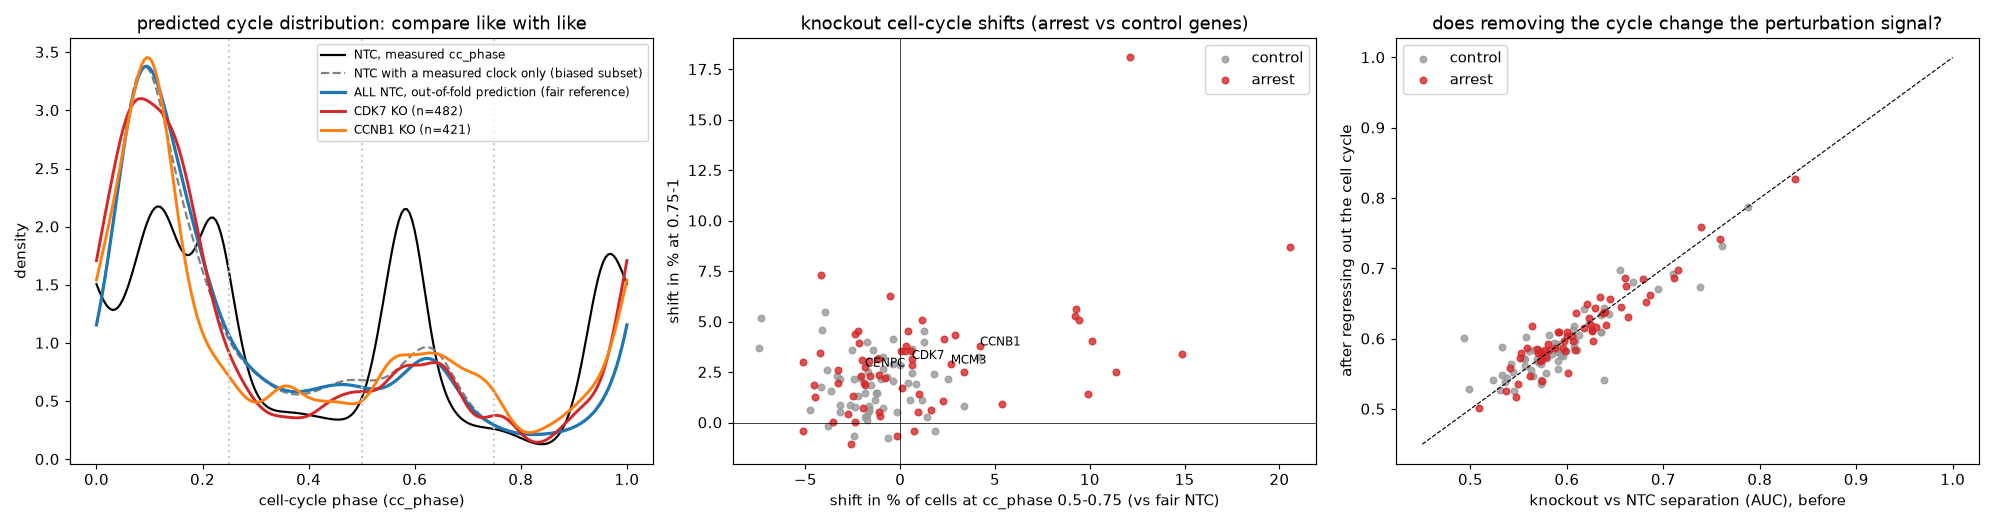

significant at FDR 5%: 8 of 120


,gene,cls,n,d_0-0.25,d_0.25-0.5,d_0.5-0.75,d_0.75-1,min_q,measured_pRb_shift_log2
81,POLE2,arrest,397,-11.71,-2.80,9.20,5.30,0.038,-0.109
80,POLE,arrest,441,-11.24,-3.27,9.41,5.10,0.038,-0.279
79,POLA2,arrest,305,-14.40,-3.86,14.84,3.42,0.038,-0.106
78,POLA1,arrest,530,-14.98,1.09,11.37,2.51,0.038,-0.056
6,AURKB,arrest,424,-12.15,-2.73,9.25,5.63,0.038,-0.440
72,NOL6,control,566,5.35,-3.22,-7.33,5.20,0.038,-0.457
18,CDC45,arrest,364,-21.40,-7.86,20.55,8.71,0.038,-0.413
69,MCM7,arrest,622,-11.08,-0.25,9.90,1.43,0.038,-0.120
84,PPP2CA,arrest,560,-1.99,-1.11,-4.20,7.31,0.054,-0.332
102,SMARCC1,arrest,767,-3.12,-1.00,0.57,3.55,0.054,-0.061


In [4]:
display(Image(filename=find('ko_cycle_overview.png')))
r = pd.read_csv(find('ko_predicted_cycle_composition.csv'))
q = [c for c in r if c.startswith('q_')]
print('significant at FDR 5%:', int((r[q].min(1) < .05).sum()), 'of', len(r))
r.assign(min_q=r[q].min(1)).sort_values('min_q').head(12)[['gene', 'cls', 'n'] + [c for c in r if c.startswith('d_') and 'labelled' not in c] + ['min_q', 'measured_pRb_shift_log2']].round(3)

In [5]:
print(open(find('ko_cycle_heterogeneity_log.txt')).read().split('variance of NTC')[0][-1600:])
pd.read_csv(find('ko3_measured_vs_predicted.csv'))

.126)] | vs labelled-only NTC [np.float64(-2.89), np.float64(-3.5), np.float64(2.53), np.float64(3.86)]
  MCM3   n= 729 shift vs fair NTC [np.float64(-8.15), np.float64(2.56), np.float64(2.67), np.float64(2.92)] q [np.float64(0.0667), np.float64(0.768), np.float64(0.4175), np.float64(0.0818)] | vs labelled-only NTC [np.float64(-6.6), np.float64(2.64), np.float64(1.0), np.float64(2.95)]
  CENPC  n= 453 shift vs fair NTC [np.float64(0.95), np.float64(-1.86), np.float64(-1.86), np.float64(2.77)] q [np.float64(0.9516), np.float64(0.8649), np.float64(0.7601), np.float64(0.2533)] | vs labelled-only NTC [np.float64(2.5), np.float64(-1.77), np.float64(-3.53), np.float64(2.8)]
mean shift per quarter (signed, all 120 genes), vs labelled-only NTC: [ 0.49 -1.12 -1.83  2.46] | vs ALL NTC (fair): [-1.06 -1.21 -0.16  2.43]
  predicted % in quarter 0-0.25 vs measured pRb shift across 120 knockouts: rho -0.18 (p=0.053)
  predicted % in quarter 0.25-0.5 vs measured pRb shift across 120 knockouts: rho +0

,gene,n,measured_4N_pct_shift,predicted_shift_0p5_0p75,predicted_shift_0p75_1
0,CCNB1,349,4.3,4.21,3.82
1,CENPC,374,-1.3,-1.86,2.77
2,MCM3,630,4.2,2.67,2.92


## 2. The whole library: which knockouts change the cell-cycle distribution

**What.** The same model applied to all 1,000 OPS0077 knockouts (591,136 cells).

**How.** For each knockout, the predicted cycle distribution is compared with NTC (total variation over 12 cycle bins), together
with its predicted change in % 4N cells. The null is NTC guides pooled to the knockout's cell count (2,000 draws), with BH FDR over
1,000 knockouts.

**Result.**
* **81 knockouts change the predicted cycle distribution**, and the direction makes biological sense:
  * **DNA replication and mitosis/cytokinesis genes gain 4N cells**, for example CDC45 (+10.5 points), MTBP (+14.3), KIF23 (+11.8),
    POLA1/POLA2/POLE/POLE2, MCM7, RRM1 and AURKB.
  * **Ribosome, translation, RNA polymerase I and chaperonin genes lose 4N cells**, for example POLR1B (-8.5), RPL27A, RPS28, TCP1,
    CCT3/6A/7 and EIF2S1. These cells accumulate before S phase, as expected for nucleolar and translational stress.
* **Validation:** the predicted change in % 4N agrees with measured pRb on the same knockout cells across all 1,000 knockouts (rho +0.37).

In [6]:
R = pd.read_csv(find('ko_library_cycle.csv'))
cols = ['gene', 'n', 'cycle_TV', 'q_cycle', 'd_pct_4N_pred', 'measured_pRb_shift_log2', 'within_vs_null_median', 'q_within', 'cycle_share_of_shift', 'auc_before', 'auc_after']
print('knockouts with a significant cycle-distribution change:', int((R.q_cycle < .05).sum()))
R[R.q_cycle < .05].sort_values('cycle_TV', ascending=False)[cols].head(25).round(3)

knockouts with a significant cycle-distribution change: 81


,gene,n,cycle_TV,q_cycle,d_pct_4N_pred,measured_pRb_shift_log2,within_vs_null_median,q_within,cycle_share_of_shift,auc_before,auc_after
762,RRM1,153,0.302,0.011,5.320,-0.285,5.806,0.001,0.127,0.751,0.726
617,POLR1B,321,0.293,0.011,-8.510,-0.507,4.780,0.001,-0.040,0.867,0.846
128,CDC45,364,0.293,0.011,10.502,-0.413,7.998,0.001,0.127,0.836,0.801
732,RPL26,182,0.264,0.011,2.391,-0.527,6.136,0.001,0.038,0.851,0.815
745,RPS10,151,0.260,0.011,-4.497,-0.502,4.389,0.001,-0.019,0.796,0.753
733,RPL27A,158,0.257,0.011,-6.041,-0.513,3.851,0.001,0.013,0.717,0.679
523,MTBP,276,0.256,0.011,14.342,-0.234,5.582,0.001,0.174,0.705,0.685
766,RSL24D1,219,0.255,0.011,-0.839,-0.500,4.683,0.001,0.014,0.749,0.732
877,TCP1,280,0.241,0.011,-6.229,-0.501,3.034,0.001,0.031,0.757,0.717
439,KIF23,235,0.239,0.011,11.784,-0.400,4.344,0.001,0.175,0.641,0.667


### 2b. Do the likely-arrest knockouts shift the way their expected arrest phase predicts?

**What.** The arrest list annotates each of its 60 genes with an expected arrest phase: G1 (26 genes), S (9) or G2/M (25).
An arrest in G1 should lower the share of 4N cells; an arrest in S or G2/M should raise it.

**How.** For each expected phase, the predicted change in % 4N cells is compared with the other 940 library knockouts (Mann-Whitney).

**Result.**
* **S-phase genes behave as expected.** 8 of 9 gain 4N cells (median +4.0 points; p = 3e-5 vs the rest of the library).
* **The G1 and G2/M groups do not differ from the library** (p 0.10 and 0.13).
* **Part of this is the annotation itself.** Several genes sit in a group that does not match their known function:
  * RRM1, POLE and RPA2 are replication genes listed under G1, and they gain 4N cells like the S group;
  * CCNB1 (the mitotic cyclin) is listed under G1;
  * CDC45 (a replication helicase factor) is listed under G2/M.
* **The mechanism text is identical within each phase group**, so the annotation looks rule-generated, not curated per gene.
* **Open question:** most mitotic and ESCRT genes (CHMP*, CENP*, BUB1B) show no predicted 4N gain. Either the knockouts are weak in
  these cells, or phase contrast does not see the arrest. Measured DNA content for these knockouts can settle it.

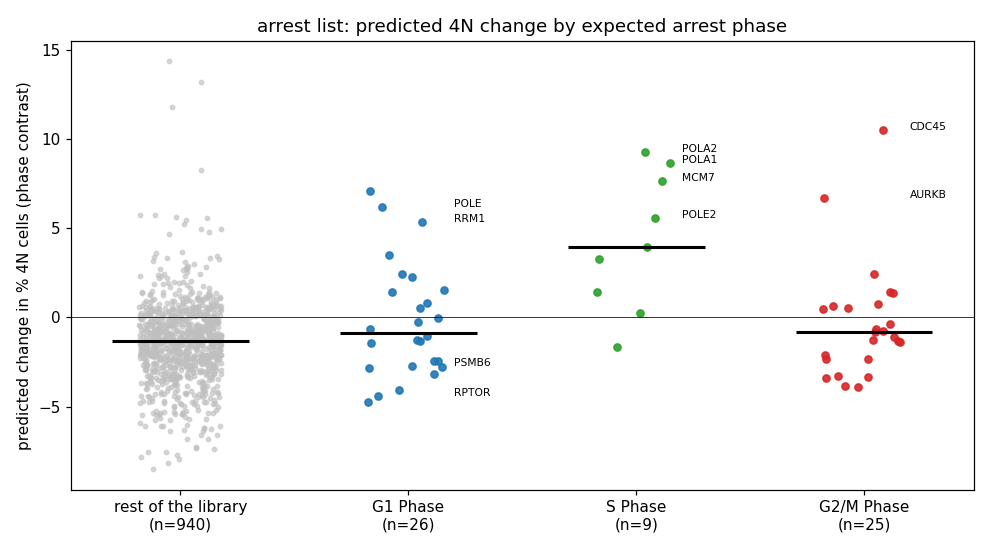

,expected_arrest_phase,n,expected_4N_change,median_predicted_d_pct_4N,fraction_4N_up,n_significant_cycle_shift,p_vs_rest_of_library
0,G1 Phase,26,down,-0.87,0.38,4,0.100000
1,S Phase,9,up,3.95,0.89,4,0.000029
2,G2/M Phase,25,up,-0.80,0.36,2,0.130000
3,rest of the library,940,NaN,-1.31,0.23,71,NaN


,gene,Gene_Name,Primary_Arrest_Phase,n,q_cycle,d_pct_4N_pred,measured_pRb_shift_log2
0,EIF4G1,eukaryotic translation initiation factor 4 gam...,G1 Phase,807,0.200,-4.730,-0.341
1,RPTOR,regulatory associated protein of MTOR complex 1,G1 Phase,662,0.035,-4.401,-0.355
2,SMARCD1,SWI/SNF related BAF chromatin remodeling compl...,G1 Phase,525,0.296,-4.060,-0.092
3,CCNG1,cyclin G1,G1 Phase,658,0.254,-3.165,-0.229
4,CCNF,cyclin F,G1 Phase,573,0.468,-2.847,-0.147
5,CCNH,cyclin H,G1 Phase,443,0.657,-2.791,-0.438
6,PSMB6,proteasome 20S subunit beta 6,G1 Phase,515,0.049,-2.706,-0.458
7,PPP2CA,protein phosphatase 2 catalytic subunit alpha,G1 Phase,561,0.356,-2.437,-0.332
8,DDRGK1,DDRGK domain containing 1,G1 Phase,820,0.270,-2.418,-0.159
9,CCND3,cyclin D3,G1 Phase,734,0.954,-1.424,-0.260


In [7]:
display(Image(filename=find('arrest_phase_test.png')))
display(pd.read_csv(find('arrest_phase_test.csv')))
pd.read_csv(find('arrest_phase_by_gene.csv'))

### 2c. A better cycle model (gradient boosting), and the library rerun with it

**What.** Brian's notebook uses gradient-boosted trees (HistGB) on all raw phase features instead of our ridge on PCA-100. Is it
better, why, and does it change the library results?

**How.** Five models predict the clock, all scored on held-out tiles (5 folds by tile, 35,633 NTC cells with a 4i clock).
*Median error* is the typical angular distance between predicted and measured clock, in degrees out of 360. The library
(section 2) was then rerun with HistGB as the angle and 4N model; everything else (out-of-fold NTC, guide-pooled null with 2,000
repeats, decomposition, heterogeneity, pRb validation) is unchanged.

**Result: model choice.**
* **HistGB on raw features is clearly better: 21.8 vs 29.3 degrees** on the DNA clock. Brian's NaN-to-0 version and a native-NaN
  version on 1,740 features are tied (21.7 and 21.8), so missing-value handling does not matter.
* **Most of the gain needs the raw features.** On PCA-100, HistGB gains only 1.0 degree over ridge (28.3) and a single-target
  network 2.5 degrees (26.8). No linear model on raw features was fitted, so "raw features" and "nonlinear on raw features"
  are not fully separated.
* **Predicting the DNA x pRb stages directly** reaches balanced accuracy 0.59 (HistGB) vs 0.52 (logistic on PCA-100), chance 0.25.
  S phase stays hard (recall 0.24 and 0.02).

**Result: library rerun.**
* **194 knockouts change the predicted cycle distribution with HistGB, against 81 with ridge** (73 in both). The two runs rank
  genes similarly (Spearman 0.79 for the size of the shift, 0.92 for the predicted change in % 4N).
* **Agreement with measured pRb is unchanged** (rho +0.38 vs +0.37 over 1,000 knockouts; +0.39 among the 121 new hits).
* **The heterogeneity result does not depend on the model.** Removing the cycle shrinks within-knockout spread by 2.75% (ridge
  3.05%), and separation from NTC is unchanged (595 knockouts before, 613 after).
* **Where the hits move.** For 162 of 194 hits the largest gain is in "G1 after division" (0.75 to 1; median +7.4 points) and for
  130 the largest loss is in G2 (0.5 to 0.625; median -5.0). The largest group of new hits (roughly 26 to 34 of 121) is ribosome,
  translation and splicing genes. Replication and mitosis knockouts (CDC45, RRM1, MTBP, KIF11) lose 21 to 28 points of G1
  (0 to 0.25) and gain cells in mitosis/division and in G1 after division.
* **Focus genes.** CDC45, MCM7 and POLA1 are significant in both runs, with larger predicted 4N gains under HistGB (+13.5, +9.8,
  +10.3 points). CDK7 moves from null (q 0.50) to borderline (q 0.057). CCNB1 is not significant in either run (q 0.19 and 0.36).

**Caveats.**
* The extra hits come from a more sensitive model under the same null; the only independent support is the pRb correlation.
* Some new hits are probably not expressed in A549 or belong to multi-copy families (for example OR2T5, TAS2R40, KRTAP2-3,
  SPRR2A, USP17L5, AGAP9). They may be false positives or guide-level effects.
* The 8 ridge-only hits are borderline under HistGB (q 0.06 to 0.14). The smallest attainable q is 0.007 (HistGB) and 0.011
  (ridge), so tiny q differences mean nothing.

In [8]:
display(pd.read_csv(find('model_compare_clock.csv')).round(3))
display(pd.read_csv(find('model_compare_stage.csv')).round(3))
print(open(find('compare_ko_ridge_hgb_log.txt')).read()[:1600])

,model,target,median_err_deg,mean_err_deg,circ_r,within_45,quarter_vs_DNAxpRb_stage_bal_acc
0,"HistGB, raw features NaN->0 (Brian)",cc_phase_dna,21.7,34.2,0.563,0.747,0.309
1,"HistGB, raw features (>=85% finite), native NaN",cc_phase_dna,21.8,34.5,0.559,0.745,0.309
2,"MLP single-target, PCA-100",cc_phase_dna,26.8,40.9,0.494,0.684,0.287
3,"HistGB, PCA-100",cc_phase_dna,28.3,42.1,0.484,0.671,0.286
4,"ridge, PCA-100 (ours)",cc_phase_dna,29.3,41.9,0.494,0.676,0.283
5,"HistGB, raw features (>=85% finite), native NaN",final cc_phase,22.2,35.3,0.560,0.733,0.307
6,"HistGB, raw features NaN->0 (Brian)",final cc_phase,22.3,35.2,0.561,0.737,0.307
7,"MLP single-target, PCA-100",final cc_phase,27.3,41.6,0.483,0.678,0.287
8,"HistGB, PCA-100",final cc_phase,29.1,43.0,0.477,0.662,0.286
9,"ridge, PCA-100 (ours)",final cc_phase,29.6,42.6,0.489,0.670,0.280


,model,balanced_accuracy,recall_Early_G1,recall_Late_G1,recall_S,recall_G2M
0,"logistic, PCA-100",0.523,0.49,0.81,0.02,0.77
1,"HistGB classifier, raw features (>=85% finite)...",0.593,0.49,0.83,0.24,0.81


genes in both: 1000
q_cycle<0.05: ridge 81, HistGB 194, both 73, ridge only 8, HistGB only 121
Jaccard 0.36
q_within<0.05: ridge 870, HistGB 851, both 848
q_4N<0.05: ridge 10, HistGB 46, both 9
class counts:
                                            ridge  HistGB
class                                                    
cells change, cycle distribution unchanged    790     664
neither                                       129     142
both                                           80     187
cycle distribution only                         1       7
Spearman across all KOs, ridge vs HistGB: cycle_TV +0.79, d_pct_4N_pred +0.92
ridge: predicted d%4N vs measured pRb shift, all 1000 KOs rho +0.371; among 81 q_cycle<0.05 KOs rho +0.406
ridge: heterogeneity median spread change -3.05% (shuffled +0.004%), median AUC change -0.0008, separate before 595, after 610, median cycle_share_of_shift -0.012
HistGB: predicted d%4N vs measured pRb shift, all 1000 KOs rho +0.378; among 194 q_cycle<0.05 KO

In [9]:
H = pd.read_csv(find('ko_library_cycle_hgb.csv'))
print('HistGB library: knockouts with a significant cycle-distribution change:', int((H.q_cycle < .05).sum()))
H[H.q_cycle < .05].sort_values('cycle_TV', ascending=False)[[c_ for c_ in cols if c_ in H]].head(25).round(3)

HistGB library: knockouts with a significant cycle-distribution change: 194


,gene,n,cycle_TV,q_cycle,d_pct_4N_pred,measured_pRb_shift_log2,within_vs_null_median,q_within,cycle_share_of_shift,auc_before,auc_after
762,RRM1,153,0.317,0.007,6.165,-0.285,5.679,0.001,0.131,0.751,0.723
756,RPS6,119,0.311,0.007,-7.325,-0.525,3.371,0.001,0.047,0.828,0.796
955,USP17L5,104,0.275,0.011,4.717,-0.482,3.751,0.001,0.092,0.809,0.766
736,RPL34,66,0.273,0.011,-6.028,-0.455,2.178,0.001,0.019,0.656,0.547
523,MTBP,276,0.271,0.007,15.378,-0.234,5.685,0.001,0.147,0.705,0.681
351,GOLGA6L1,189,0.262,0.007,8.107,-0.463,4.650,0.001,0.122,0.728,0.699
128,CDC45,364,0.255,0.007,13.486,-0.413,8.021,0.001,0.118,0.836,0.798
617,POLR1B,321,0.255,0.007,-6.287,-0.507,4.239,0.001,0.055,0.867,0.845
733,RPL27A,158,0.253,0.007,-5.629,-0.513,3.541,0.001,0.075,0.717,0.677
435,KIF11,76,0.253,0.031,14.221,-0.468,2.064,0.001,0.211,0.645,0.566


### 2d. Measured DNA for 111 knockouts, and Brian's hypertrophy test

**What.** Are the predicted cycle shifts real? And does Brian's concern hold, that G1-arrested cells keep growing and are then
called G2/M by phase contrast?

**How.**
* **Knockouts:** the 81 with a predicted cycle shift (ridge library, q_cycle < 0.05) and 30 calibration knockouts with none.
* **DNA per cell:** background-corrected DAPI, rounds 2 to 4, log2 relative to the 2N peak. 2N below 0.25, S 0.25 to 0.65, 4N above
  0.65 (the NTC cut-offs). 22,152 of 26,628 measured cells kept (a nucleus in all three rounds, one nucleus per cell).
* **Test:** change in % 2N and % 4N vs NTC guides pooled to the same cell count (2,000 draws), BH FDR separately for each; a
  knockout is "confirmed" if either passes at 5%.
* **Hypertrophy:** four 4N-vs-not phase models trained on NTC and scored on knockout cells with measured DNA. *Standard* (the
  model used so far), *size-balanced* (trained so that size alone cannot separate 2N from 4N), *size-removed* (cell area regressed
  out of the features), and *DNA floor* (Brian's rule: no 4N call below 2.5N of phase-predicted DNA).

**Result: the predictions hold.**
* **Predicted vs measured change in % 4N: Spearman 0.76, Pearson 0.84, slope 1.01** (n = 111; 0.63 within the 30 calibration
  knockouts alone). Predicted shifts are on the right scale.
* **42 of 81 predicted shifters are confirmed** (16 on % 4N, 26 on % 2N only), and 41 of the 42 have the predicted sign (the exception
  is SNRPG). 38 of the 42 lose 4N cells: ribosome-biogenesis, proteasome, chaperone and splicing genes such as HSPA9 (-11.6 points),
  IMP4, PSMD4, SRSF3 and WDR12. The 4 confirmed 4N gains are all DNA replication genes: MTBP +17.0, MCM7 +12.2, CDC45 +8.4,
  POLA2 +7.9.
* **7 of 30 calibration knockouts also shift**, always in the predicted direction and in 6 of 7 more strongly than predicted (MED6:
  predicted -3.3, measured -9.9). The largest is the mitotic kinesin KIF11 (+19.5 points 4N, n = 67). So the library misses some real
  shifts. The 39 unconfirmed shifters may be false positives or may reflect limited power at about 200 cells; this set cannot tell.

**Result: the hypertrophy idea is not supported.**
* **Within NTC there is a size bias:** the standard model calls 3.4% of 2N cells 4N, but 15.6% of the largest tenth of 2N cells.
* **Across knockouts it does not matter.** Measured-2N cells are larger than NTC 2N cells in 102 of 111 knockouts (median about 17%
  more area), yet the excess of false 4N calls over NTC has median -1.0 point and does not rise with 2N cell size (Spearman 0.08,
  p 0.41).
* **The G1-list knockouts in this batch** (CUL1, POLE, PSMB6, RPTOR, RRM1) have false-4N excesses of -1.1 to +0.7 points. RPTOR, the
  only one with a significant measured shift, gains 2N cells (+15.2 points) and phase contrast predicts that direction.
* **Correcting for size makes things worse:** agreement with measured DNA across knockouts is 0.86 (standard), 0.86 (DNA floor), 0.75
  (size-balanced) and 0.69 (size-removed). **The DNA floor changes no knockout by more than 0.63 points**; it is a harmless safety check.

**Caveats.** The 81 shifters were chosen for having predicted shifts, which helps the correlation. With 2,000 draws the smallest p is
about 0.0005, and some large shifts miss significance (GOLGA6L1 +8.8 points, q 0.08). Confirming on either % 2N or % 4N lets the
combined FDR exceed 5% somewhat. The 4N cut (0.65 log2, about 3.1N) counts late-S cells as 4N, which matters for the replication
genes. Only 5 G1-list knockouts are in this batch; the remaining 47 arrest-list genes are being measured.

**Data.** Every phase-imaged cell of these 111 knockouts (53,471) with 4i, phase contrast and measured DNA where measured:
`/srv/team/data/crossmodal/ops0077_ko/OPS0077_KOcyc_Multimodal_4i_Phase_DNA.h5ad` (same schema and NTC scaling as the NTC file).
pRb, Rb and p21 are missing for 19% of cells, so 3,406 measured 2N-range cells have no `cycle_stage`.

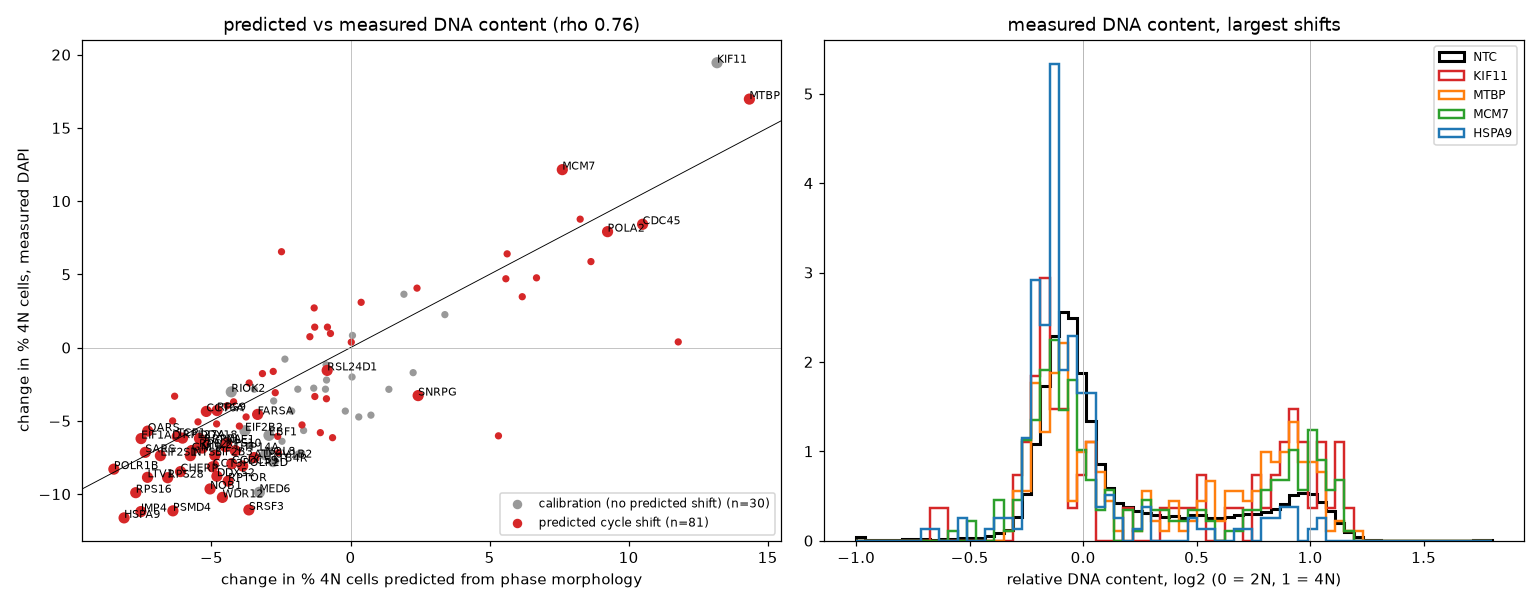

,gene,set,n_measured,measured_d_pct_2N,measured_d_pct_4N,q_2N,q_4N,predicted_d_pct_4N,measured_significant
39,HSPA9,cycle_shift,194,19.001,-11.624,0.002,0.018,-8.142,True
40,IMP4,cycle_shift,196,18.606,-11.193,0.002,0.018,-7.538,True
71,PSMD4,cycle_shift,207,20.196,-11.144,0.002,0.018,-6.386,True
103,SRSF3,cycle_shift,145,17.927,-11.080,0.002,0.044,-3.654,True
109,WDR12,cycle_shift,219,18.012,-10.224,0.002,0.039,-4.606,True
...,...,...,...,...,...,...,...,...,...
11,CDC45,cycle_shift,216,-18.270,8.421,0.002,0.049,10.502,True
35,GOLGA6L1,cycle_shift,160,-5.909,8.769,0.308,0.077,8.258,False
50,MCM7,cycle_shift,219,-11.668,12.150,0.016,0.018,7.615,True
53,MTBP,cycle_shift,223,-19.883,16.966,0.002,0.018,14.342,True


In [10]:
display(Image(filename=find('ko_measured_vs_predicted_dna.png')))
M = pd.read_csv(find('ko_measured_vs_predicted_dna.csv'))
M.sort_values('measured_d_pct_4N')[['gene', 'set', 'n_measured', 'measured_d_pct_2N', 'measured_d_pct_4N', 'q_2N', 'q_4N', 'predicted_d_pct_4N', 'measured_significant']].round(3)

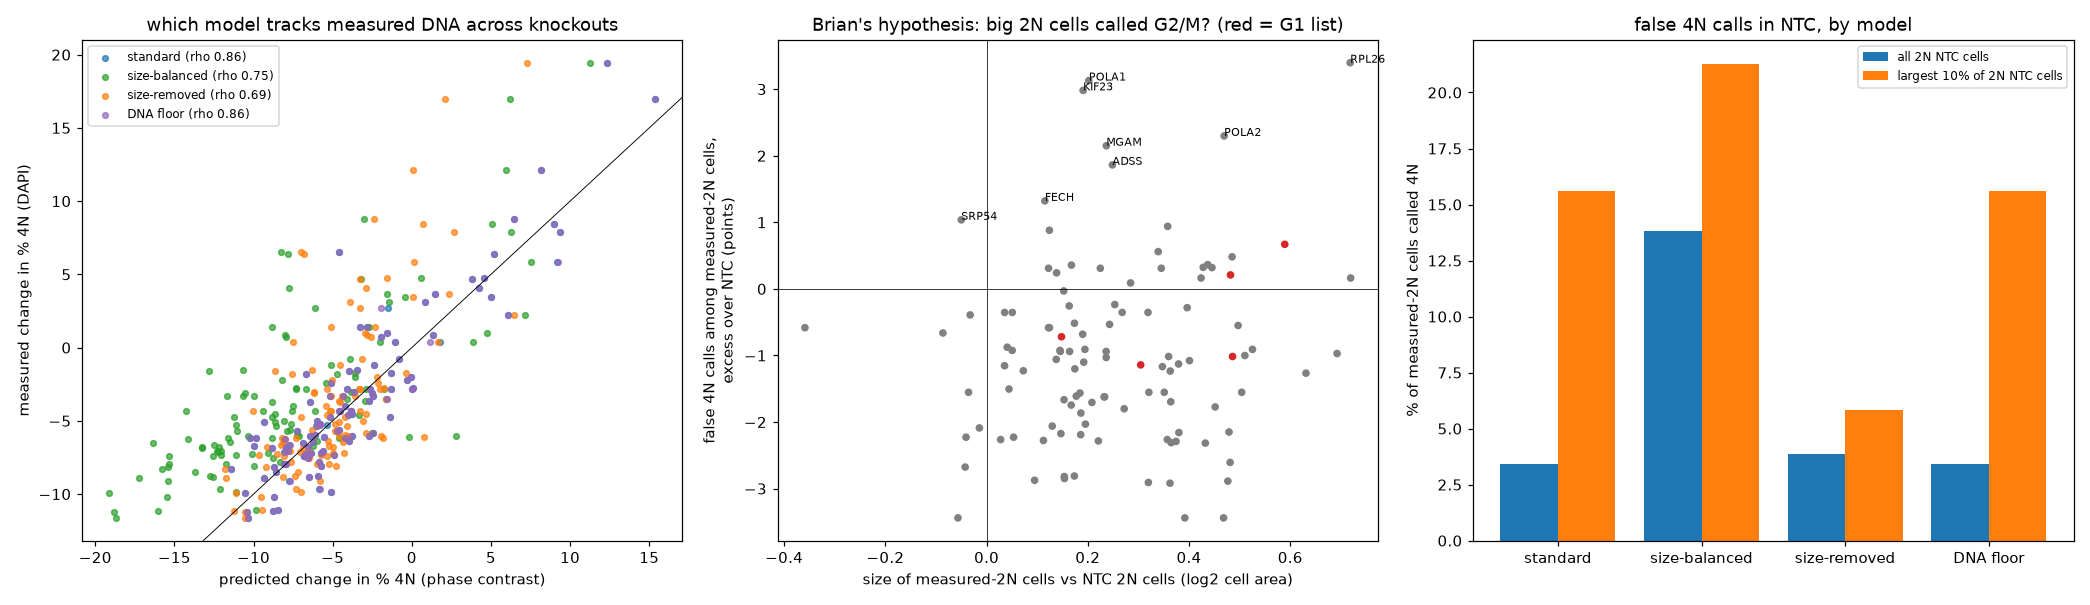

,model,NTC_AUC_4N,NTC_pred_pct_4N,NTC_measured_pct_4N,NTC_2N_false_4N_pct,NTC_largest_2N_false_4N_pct,AUC_of_cell_size_alone,NTC_measured_4N_called_4N_pct
0,standard,0.919,16.0,19.4,3.44,15.62,0.709,63.2
1,size-balanced,0.902,30.6,19.4,13.81,21.28,0.709,84.6
2,size-removed,0.886,13.6,19.4,3.86,5.82,0.709,50.2
3,DNA floor,0.920,16.0,19.4,3.43,15.62,0.709,63.2


,model,spearman_pred_vs_measured_d4N,pearson,median_false_4N_excess_points,G1_list_median_false_4N_excess
0,standard,0.859,0.905,-1.03,-0.72
1,size-balanced,0.752,0.768,-3.81,-3.59
2,size-removed,0.687,0.704,-1.45,-1.67
3,DNA floor,0.858,0.905,-1.02,-0.71


In [11]:
display(Image(filename=find('g1_hypertrophy_check.png')))
display(pd.read_csv(find('model_summary_ntc.csv')).round(3))
pd.read_csv(find('model_vs_measured_across_knockouts.csv')).round(3)

## 3. Regressing the cycle out: does heterogeneity go down?

**What.** The project hypothesis: removing the cell-cycle component from perturbation profiles should reduce the apparent heterogeneity
of perturbed populations.

**How.**
* **What is removed.** From every phase-contrast dimension (PCA-100) we remove the part explained by the predicted cycle (sine and
  cosine, first and second harmonics). The coefficients are fit on NTC cells using out-of-fold predictions.
* **Heterogeneity** is measured two ways: the spread of each knockout population (mean distance to its centroid), and how separable
  it is from NTC (held-out logistic AUC).
* **Controls.** A shuffled cycle is the control. A knockout counts as "separating" when its AUC is above the 95th percentile of NTC
  guide pools of the same size.

**Result: heterogeneity barely changes.**
* **Spread** falls by a median of **3.0%** (shuffled cycle: +0.004%), the same for arrest and non-arrest knockouts.
* **Separation from NTC** is essentially unchanged: median AUC change -0.001. 595 knockouts separate from NTC before and 610 after,
  so removing the cycle neither erases perturbation signal nor sharpens it overall.
* **Per-knockout AUC changes are noise; do not read them gene by gene.** Two independent runs on the same 120 knockouts reproduce
  the AUC itself (r 0.91), but not the before-to-after change (r 0.02; the run-to-run difference, SD 0.036, is as large as the
  changes). Which knockouts' phenotypes are "mostly cell cycle" is answered by the deterministic decomposition in section 4:
  the cycle shift explains at most about a quarter of any knockout's morphology change.

**Why so little:** the cell cycle is a *predictable* but *low-variance* direction of phase morphology. Even the **measured** cycle
explains only 2.9% (harmonics 1 to 2) to 5.7% (all four 4i readouts) of NTC phase-morphology variance, while the first principal
component alone explains 12.3%.

percent of NTC phase-morphology variance (PCA-100) explained by:
  measured cc_phase, harmonics 1-2                 2.9%
  measured cc_phase, harmonics 1-4                 3.5%
  measured DNA content (cubic)                     2.4%
  measured DNA+pRb+p21+phos (linear+squares)       5.7%
  shuffled cc_phase                                0.0%
for scale: PC1 alone explains 12.3 % of the PCA-100 variance



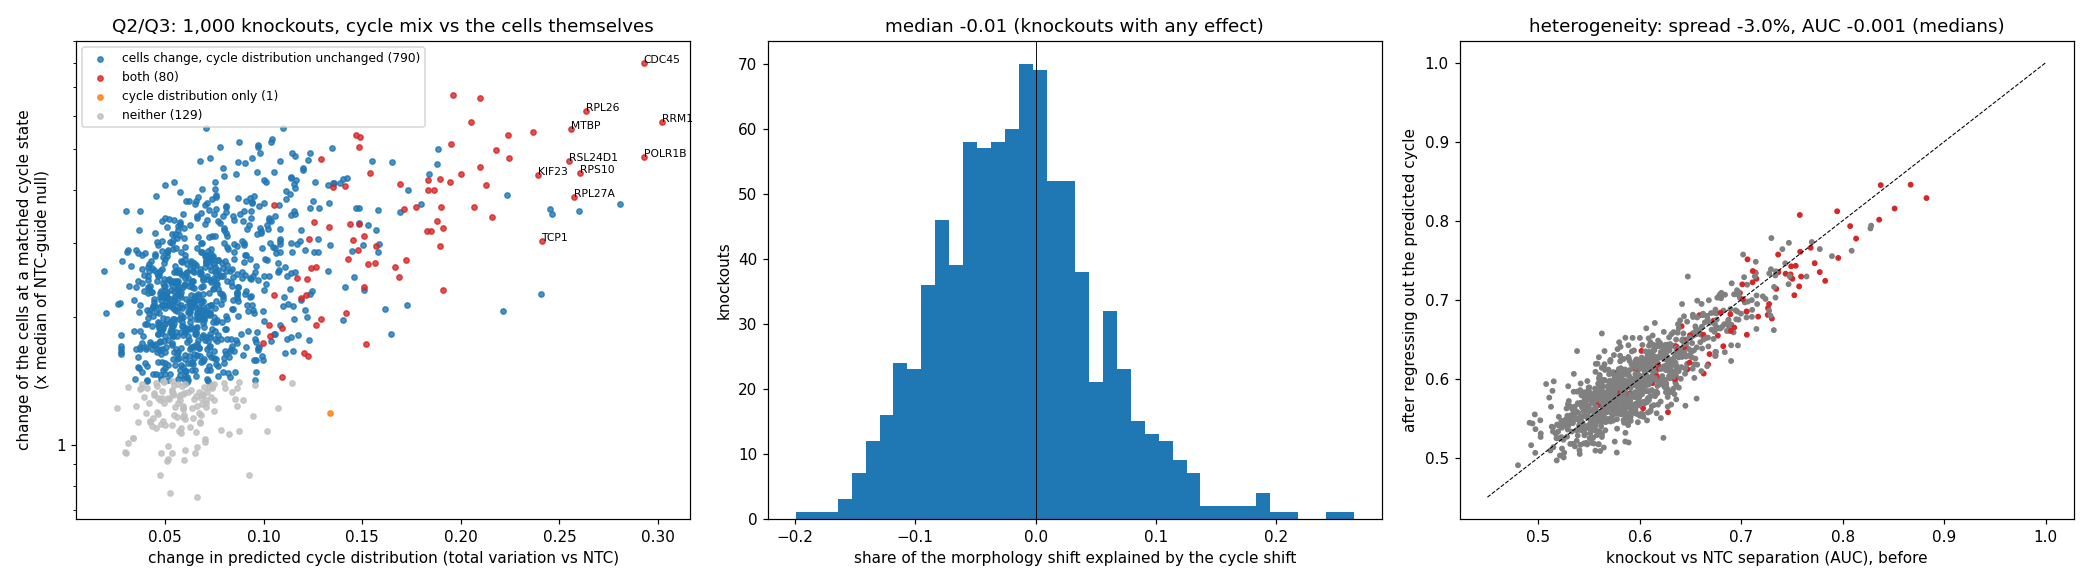

,spread_change_pct,spread_change_shuffled_pct,auc_before,auc_after,auc_change
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,-3.064,0.004,0.606,0.604,-0.001
std,0.425,0.007,0.060,0.057,0.027
min,-5.479,-0.025,0.480,0.490,-0.098
25%,-3.266,-0.000,0.565,0.565,-0.019
50%,-3.046,0.004,0.593,0.594,-0.001
75%,-2.801,0.009,0.633,0.634,0.016
max,-1.772,0.033,0.883,0.846,0.097


In [12]:
print(open(find('cycle_variance_bound.txt')).read())
display(Image(filename=find('library_cycle_decomposition.png')))
R[['spread_change_pct', 'spread_change_shuffled_pct', 'auc_before', 'auc_after', 'auc_change']].describe().round(3)

In [13]:
# reproducibility of per-knockout AUC values and AUC changes: the 120-gene run (section 1) vs the library run, same knockouts
a = pd.read_csv(find('ko_heterogeneity_before_after.csv')); m = a.merge(R, on='gene', suffixes=('_120', '_library'))
pd.Series({'knockouts in both runs': len(m),
           'AUC before, r between runs': m.auc_before_120.corr(m.auc_before_library),
           'AUC after, r between runs': m.auc_after_120.corr(m.auc_after_library),
           'AUC change, r between runs': m.auc_change_120.corr(m.auc_change_library),
           'SD of the run-to-run difference in AUC change': (m.auc_change_120 - m.auc_change_library).std(),
           'SD of AUC change across the library': R.auc_change.std()}).round(3)

knockouts in both runs                           120.000
AUC before, r between runs                         0.912
AUC after, r between runs                          0.890
AUC change, r between runs                         0.018
SD of the run-to-run difference in AUC change      0.036
SD of AUC change across the library                0.027
dtype: float64

## 4. Three questions about normalising by the cell cycle

Does normalising or weighting cell-cycle scores (1) reduce field and well heterogeneity, (2) find perturbations that change the
cell-population distribution, or (3) separate those from perturbations that only change the cells?

**Two normalisations:**
* **regress**: remove the cycle-explained part of every morphology dimension;
* **reweight**: weight reference cells so that their cycle distribution matches the target.

**Two datasets:**
* **OPS0077**: phase contrast; cycle predicted from morphology, with the measured 4i clock as a check.
* **Element**: imaging features; cycle **measured from RNA**, so it cannot be circular with morphology. It includes a TNFa stimulus and 5 knockouts.

### Q1. Field and well heterogeneity: not reduced

**How.** For control cells we measure the share of morphology variance that lies **between wells or between fields** (tiles with at
least 30 cells), minus what random sampling alone gives (permuted labels).

**Result.**
* **With a measured clock, normalisation changes almost nothing:**
  * Element wells: 1.67% before, 1.72% after regressing, 1.67% after reweighting.
  * Element fields: 7.2%, 7.4%, 7.2%.
  * OPS0077 fields: 7.9%, 7.8%, 7.9%.
* **The apparent reduction with the predicted cycle (OPS0077 fields 12.4% to 10.7%) is circular.** Wells do not differ in measured
  cycle composition beyond chance (spread across wells of the share of cells in the second half of the clock, 0.34% vs 0.32% if random), but they do in predicted
  composition (2.8% vs 0.2%). The predictor reads a technical well difference as "cycle".
* **Why:** fields do differ somewhat in measured cycle composition (local density), but that difference explains at most about 2% of the field effect.

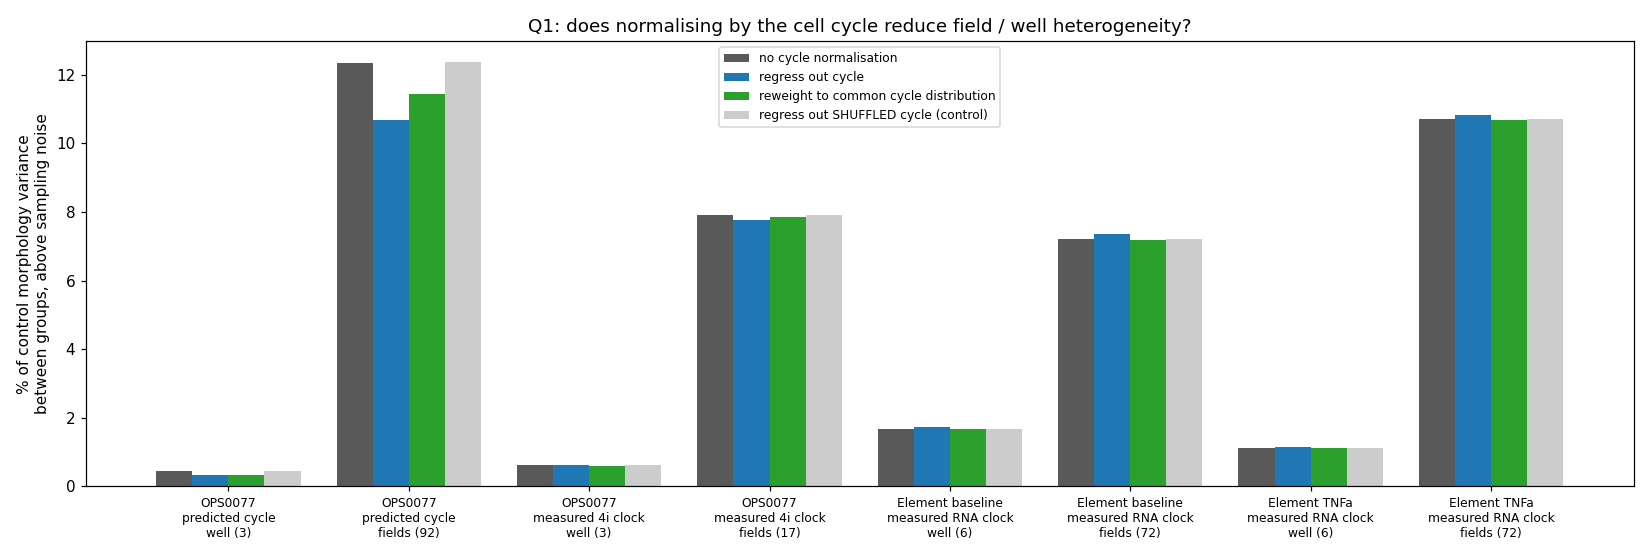

,dataset,grouping,n_groups,arm,between_share_pct,noise_floor_pct,excess_pct,sd_across_groups_of_late_cycle_share_pct,same_if_random_pct
0,"OPS0077 (predicted cycle, all NTC)",well,3,no cycle normalisation,0.448,0.004,0.444,2.76,0.21
1,"OPS0077 (predicted cycle, all NTC)",well,3,regress out cycle,0.332,0.004,0.328,2.76,0.21
2,"OPS0077 (predicted cycle, all NTC)",well,3,reweight to common cycle distribution,0.327,0.004,0.324,2.76,0.21
3,"OPS0077 (predicted cycle, all NTC)",well,3,regress out SHUFFLED cycle (control),0.448,0.004,0.445,2.76,0.21
4,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,no cycle normalisation,15.187,2.830,12.357,13.66,7.61
5,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,regress out cycle,13.529,2.835,10.694,13.66,7.61
6,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,reweight to common cycle distribution,14.737,3.286,11.451,13.66,7.61
7,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,regress out SHUFFLED cycle (control),15.185,2.818,12.368,13.66,7.61
8,"OPS0077 (MEASURED 4i clock, labelled NTC)",well,3,no cycle normalisation,0.641,0.006,0.635,0.34,0.32
9,"OPS0077 (MEASURED 4i clock, labelled NTC)",well,3,regress out cycle,0.639,0.005,0.634,0.34,0.32


In [14]:
display(Image(filename=find('q1_field_well_heterogeneity.png')))
pd.read_csv(find('q1_field_well_heterogeneity.csv'))

### Q2 and Q3. Cycle mix versus the cells themselves

**How.** Each perturbation's morphology shift (centroid vs control) is split exactly into two parts:
* **cycle-mix part**: the shift control cells would show if they had the perturbation's cycle distribution (reweighting);
* **matched-cycle part**: the remaining shift, at a matched cycle state.

Each part is tested against the same null as above (NTC guides pooled to n for OPS0077). For Element the null is halves of baseline
wells for TNFa, and single control guides for the knockouts.

**Result (OPS0077, 1,000 knockouts).**

| class | knockouts |
|---|---|
| cells change, cycle distribution unchanged | 790 |
| both | 80 |
| cycle distribution only | 1 (HSPA14) |
| neither | 129 |

**Even among knockouts that shift the cycle, the cycle shift explains little of the morphology change** (median share 0.01, 10th to
90th percentile -0.11 to +0.16).

**Result (Element, measured RNA clock).**
* **TNFa** shifts the cycle distribution slightly (TV 0.038 vs largest null 0.028) and moves morphology a lot (shift 17.8), but its
  cycle-mix part is 0.3% of that.
* **CTNNB1 and TGFBR2 knockouts** shift the cycle (CTNNB1 clearly), yet their cycle-mix part is under 2% of their morphology change.

**So:**
* **(2) yes**, cycle distribution changes can be found, best with a measured clock;
* **(3) yes**, the decomposition separates the two, and in both datasets perturbations that change morphology do so at a matched cycle state. None acts only by changing the cycle mix.

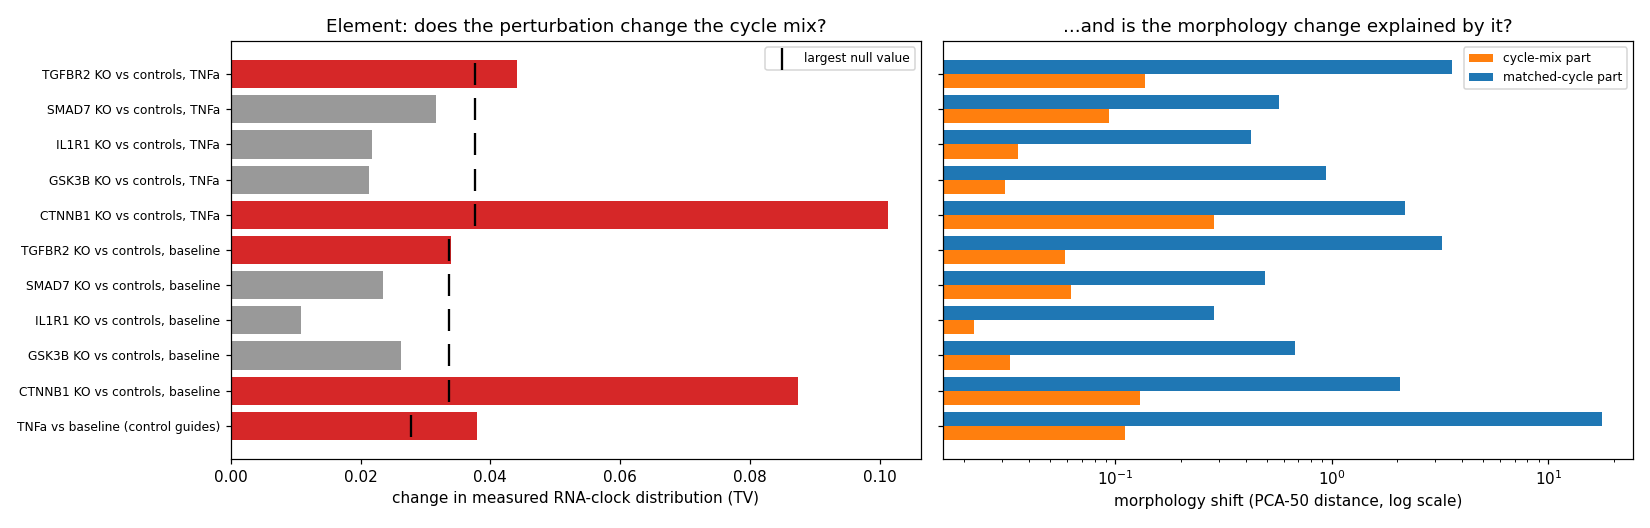

,cycle_TV,total_shift,cycle_part,within_cycle_part,cycle_share_of_shift,contrast,n,null,null_max_cycle_TV,null_max_within,cycle_beyond_null,within_beyond_null
0,0.038,17.752,0.111,17.701,0.003,TNFa vs baseline (control guides),47130,baseline wells split in halves,0.028,2.936,True,True
1,0.087,2.023,0.130,2.064,-0.018,"CTNNB1 KO vs controls, baseline",23290,single control guide vs other control guides,0.034,0.782,True,True
2,0.026,0.672,0.033,0.674,-0.002,"GSK3B KO vs controls, baseline",16792,single control guide vs other control guides,0.034,0.782,False,False
3,0.011,0.281,0.022,0.284,-0.008,"IL1R1 KO vs controls, baseline",7109,single control guide vs other control guides,0.034,0.782,False,False
4,0.023,0.529,0.062,0.489,0.079,"SMAD7 KO vs controls, baseline",5115,single control guide vs other control guides,0.034,0.782,False,False
5,0.034,3.270,0.058,3.240,0.010,"TGFBR2 KO vs controls, baseline",3577,single control guide vs other control guides,0.034,0.782,True,True
6,0.101,2.096,0.284,2.183,-0.033,"CTNNB1 KO vs controls, TNFa",22058,single control guide vs other control guides,0.038,0.598,True,True
7,0.021,0.915,0.031,0.937,-0.023,"GSK3B KO vs controls, TNFa",17160,single control guide vs other control guides,0.038,0.598,False,True
8,0.022,0.420,0.035,0.422,-0.001,"IL1R1 KO vs controls, TNFa",6618,single control guide vs other control guides,0.038,0.598,False,False
9,0.032,0.595,0.094,0.567,0.058,"SMAD7 KO vs controls, TNFa",5060,single control guide vs other control guides,0.038,0.598,False,False


In [15]:
display(Image(filename=find('element_cycle_decomposition.png')))
pd.read_csv(find('q23_element_decomposition.csv')).round(3)

## 5. A cell-cycle representation of the CROP-seq knockouts, mapped to phase contrast

**The data.** The Altair CROP-seq data are public only at knockout level: DESeq2 knockout-vs-control statistics for 1,000 knockouts
x 9,999 genes. There are no single cells, so the representation is per knockout. The CROP-seq cells are not the imaged cells; the
knockout is the link.

**How the representation is built.**
* **Cycling genes from single cells.** Element (A549, single-cell RNA with a measured RNA clock) gives the expression of every gene
  around the cycle. We keep 397 strongly cycling genes: peak-to-trough at least 0.8 log2, and the same profile in two halves of the
  wells (r at least 0.8).
* **Programmes.** Genes are grouped by where they peak: S, G2/M or G1, using Element's own phase calls and DNA content per clock bin.
* **Score per knockout.** The mean DESeq2 statistic over each programme (the knockout's own gene excluded), as a z-score against
  1,000 random gene sets matched for expression.
* **A composition deconvolution was also tried and is a documented negative.** It models the knockout as a re-weighting of cells
  along the control clock. It was not reproducible across halves of the genes (rho 0.05), and 0 of 997 knockouts passed its null.

**Result: the CROP-seq cycle signal is weak and mostly absent.**
* **Few knockouts move a programme.** 14 of 997 move any programme beyond |z| 4.
* **One standout.** SMARCD1 (S z -12, G2/M z -18) stands out. In phase contrast it does not shift the predicted cycle distribution (q 0.30).
* **Reliability is weak across all knockouts** (G2/M programme split-half 0.23), though high among the few strong ones (G1: 0.95).
* **The canonical arrest genes are flat in CROP-seq RNA** (CCNB1, CDK7, AURKB, CDC45, POLA1: all |z| < 3), although several are
  strong in imaging.

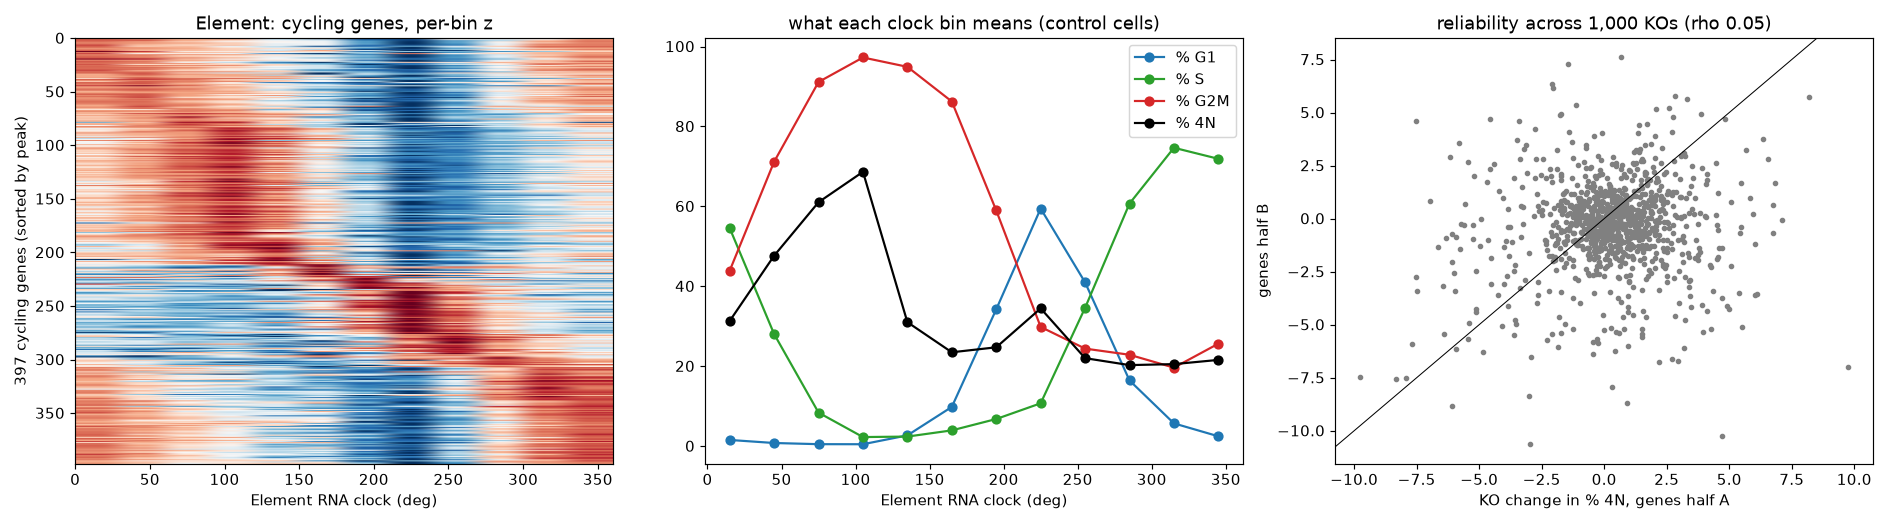

,programme,n_genes,split_half_pearson_all,split_half_spearman_all,n_strong_KOs,split_half_pearson_strong
0,S,131,0.039,-0.020,1,NaN
1,G2M,180,0.225,0.143,4,NaN
2,G1,75,0.162,0.146,10,0.947


,gene,z_S,z_G2M,z_G1
813,SMARCD1,-12.38,-18.47,1.48
891,TIPARP,1.05,2.92,5.52
570,NUP54,-0.40,1.63,4.66
861,SYVN1,0.78,1.17,4.60
372,HAUS4,-2.30,-4.47,1.90
362,GTF2A2,3.03,1.59,-4.28
284,ELP2,-0.34,4.26,2.36
806,SLC38A6,0.86,1.76,4.20
867,TARS,1.07,0.97,4.18
532,NAPA,-1.35,-0.14,4.12


In [16]:
display(Image(filename=find('crop_cycle_overview.png')))
display(pd.read_csv(find('crop_programme_reliability.csv')))
P = pd.read_csv(find('crop_cycle_programmes.csv'))
P.assign(z_max=P[['z_S', 'z_G2M', 'z_G1']].abs().max(1)).nlargest(15, 'z_max')[['gene', 'z_S', 'z_G2M', 'z_G1']].round(2)

**Mapping to phase-contrast morphology, two routes.**
* **Route 1, per cell, no RNA used for training.** The NTC-trained morphology model predicts each knockout's change in % 4N cells, which we compare with its RNA programmes.
* **Route 2, gene level.** A ridge regression from the knockout's mean phase profile to its RNA programme scores, 10-fold cross-validated across knockouts, against permuted labels.
* **Strength control.** Essential-gene knockouts move every readout, so agreement is also given after partialling out overall perturbation strength in each modality.

**Result: phase contrast and CROP-seq agree only weakly on the cell cycle.**
* **Route 1:** RNA G2/M programme vs morphology-predicted change in % 4N gives rho 0.11 (p 7e-4; 0.12 after the strength control).
* **Route 2:** cross-validated rho is 0.10 to 0.16 for the G2/M, G1 and proliferation scores, above the permuted 95th percentile
  (at most 0.03), but R2 is at most 0.09. The S programme is not predicted at all (rho -0.10).
* **The two modalities disagree on which knockouts change the cycle.** None of the 14 strongest RNA knockouts is significant in
  morphology, and the strongest morphology knockouts (RRM1, CDC45, POLR1B, ribosomal genes) show no RNA programme shift.

**Possible reasons** (not tested here): the two screens are different experiments (cells, time point, selection); knockout-level
pseudobulk dilutes a shift carried by part of the cells; and CROP-seq self-knockdown was weak for several targets. **For cell-cycle
readouts of these knockouts, the imaging data (phase contrast, validated against 4i pRb and DNA) are the stronger source.**

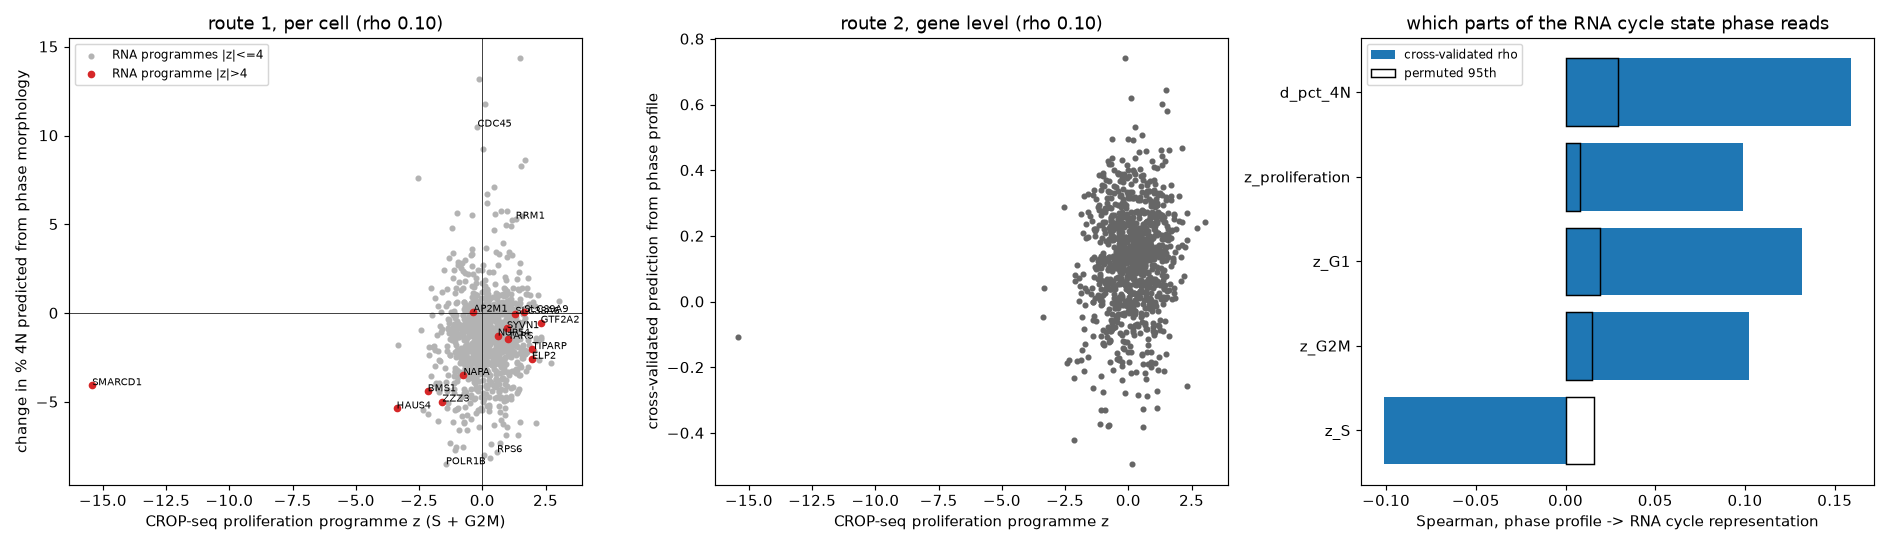

,comparison,n,spearman,p,partial_spearman_given_strength,fraction
0,RNA G2M programme z vs morphology-predicted ...,997,0.108,0.00066,0.124,NaN
1,RNA proliferation z (S+G2M) vs morphology-pr...,997,0.096,0.00230,0.115,NaN
2,RNA G1 programme z vs morphology-predicted d%4N,997,-0.038,0.23000,-0.011,NaN
3,RNA strongest programme |z| vs morphology cy...,997,0.014,0.66000,-0.038,NaN
4,RNA proliferation z vs measured pRb (4i),997,0.074,0.01900,0.099,NaN
5,RNA composition deconvolution d%4N (secondary)...,997,0.057,0.07300,0.067,NaN
6,KOs with a strong RNA programme shift (|z|>4):...,14,NaN,NaN,NaN,0.000
7,"same, all other KOs",983,NaN,NaN,NaN,0.083


,target,n,cv_R2,cv_spearman,null_95th,partial_spearman_given_strength
0,z_S,997,-0.004,-0.101,0.016,-0.127
1,z_G2M,997,0.022,0.102,0.015,0.105
2,z_G1,997,0.013,0.132,0.019,0.130
3,z_proliferation,997,0.018,0.099,0.008,0.096
4,d_pct_4N,997,0.091,0.159,0.029,0.140


In [17]:
display(Image(filename=find('crop_to_phase_overview.png')))
display(pd.read_csv(find('route1_per_cell_agreement.csv')))
pd.read_csv(find('route2_gene_level_cv.csv'))

## Takeaways

1. **Fair comparisons change the knockout story.** With all NTC cells as an out-of-fold reference and a guide-pooled null, CDK7 and
   CCNB1 shift by about +3 to +4 points (not significant), not +7 to +11. Across the library, 81 of 1,000 knockouts change the
   predicted cycle distribution, with sensible biology (replication and mitosis genes gain 4N cells; ribosome, translation and
   chaperonin genes lose them), validated by measured pRb (rho 0.37) and by **measured DNA** for 111 knockouts (predicted vs measured
   change in % 4N: Spearman 0.76, slope 1.01; 42 of 81 shifts confirmed, 41 with the predicted sign). Gradient boosting on raw phase
   features is the better cycle model (21.8 vs 29.3 degrees) and finds 194 shifting knockouts with the same pRb agreement.
   **Brian's hypertrophy concern is not supported:** knockout 2N cells are larger but not called G2/M more often, and his DNA floor
   changes nothing.
2. **Regressing the cell cycle out does not reduce the heterogeneity of perturbed populations in a meaningful way.** Spread falls by
   about 3% and separation from NTC is unchanged (595 vs 610 knockouts), because the cycle explains only 3 to 6% of phase-morphology
   variance even when measured. Per-knockout AUC changes are not reproducible between runs, so only the aggregate is interpretable.
3. **Normalising by the cycle does not remove field or well effects** (no change with a measured clock). Doing it with a
   morphology-predicted cycle looks helpful only because the predictor absorbs technical differences.
4. **The cycle-mix vs matched-cycle decomposition is the useful output.** It finds perturbations that change the cycle distribution
   and shows that, in both OPS0077 and Element, morphology changes happen at a matched cycle state; none of 1,000 knockouts acts only through the cycle mix.
5. **CROP-seq knockout-level RNA carries little cell-cycle signal** that agrees with imaging (rho about 0.1). The Element single-cell
   data remain the only place where RNA and imaging cell-cycle state are measured in the same cells.